Training Shape : (60000, 785)
Testing Shape : (10000, 785)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                      │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.8326 - loss: 0.6389 - val_accuracy: 0.9151 - val_loss: 0.3131
Epoch 2/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9169 - loss: 0.2932 - val_accuracy: 0.9289 - val_loss: 0.2518
Epoch 3/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9312 - loss: 0.2415 - val_accuracy: 0.9378 - val_loss: 0.2172
Epoch 4/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9410 - loss: 0.2073 - val_accuracy: 0.9450 - val_loss: 0.1917
Epoch 5/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9485 - loss: 0.1816 - val_accuracy: 0.9497 - val_loss: 0.1718
Epoch 6/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9544 - loss: 0.1613 - val_accuracy: 0.9543 - val_loss: 0.1562
Epoch 7/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9589 - loss: 0.1449 - val_accuracy: 0.9590 - val_loss: 0.1437
Epoch 8/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9629 - loss: 0

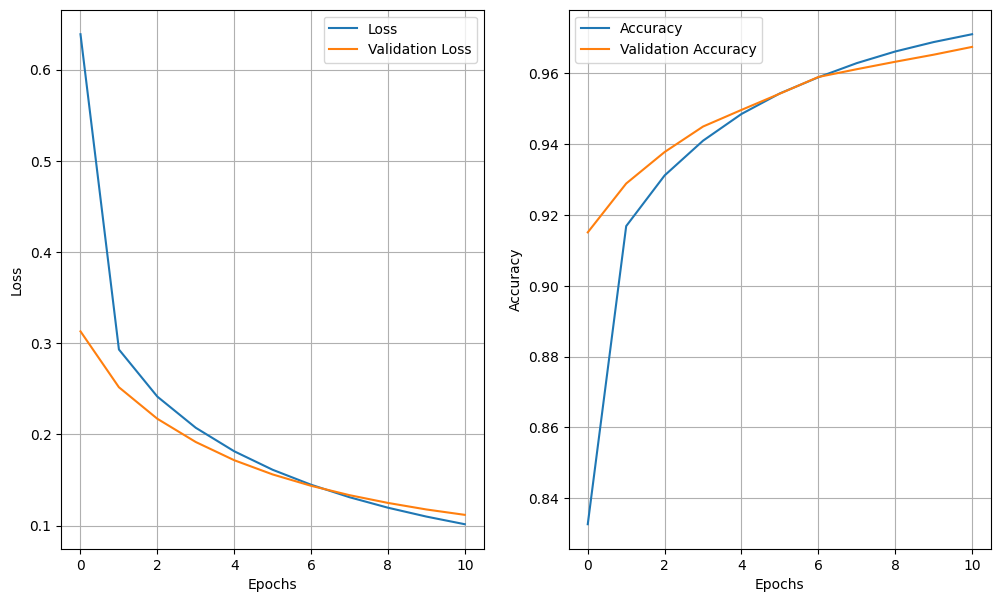

In [22]:
import numpy as np
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

train_data = pd.read_csv("mnist_train.csv")
test_data = pd.read_csv("mnist_test.csv")

train_data.head()

print("Training Shape :", train_data.shape)
print("Testing Shape :", test_data.shape)

x_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values

x_test = test_data.drop('label', axis=1).values
y_test = test_data['label'].values

x_train = x_train/255.0
x_test = x_test/255.0

model = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.summary()


model.compile(
    optimizer = keras.optimizers.SGD(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(x_train, y_train, batch_size=32, epochs=11, validation_data=(x_test,y_test))

loss, accuracy = model.evaluate(x_test,y_test)

print("Loss : ", loss)
print("Accuracy : ", accuracy);

plt.figure(figsize=(12,7))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label="Loss")
plt.plot(history.history['val_loss'], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label="Accuracy")
plt.plot(history.history['val_accuracy'], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

Training Shape : (60000, 785)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.0984 - loss: 0.0224 - val_accuracy: 0.0980 - val_loss: 2908.0181
Epoch 2/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 19s 5ms/step - accuracy: 0.0987 - loss: 4.0898e-04 - val_accuracy: 0.0980 - val_loss: 3213.7185
Epoch 3/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.0987 - loss: 2.2615e-04 - val_accuracy: 0.0980 - val_loss: 3394.8528
Epoch 4/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.0987 - loss: 1.5532e-04 - val_accuracy: 0.0980 - val_loss: 3524.5024
Epoch 5/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.0987 - loss: 1.1776e-04 - val_accuracy: 0.0980 - val_loss: 3625.7361
Epoch 6/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.0987 - loss: 9.4546e-05 - val_accuracy: 0.0980 - val_loss: 3708.8933
Epoch 7/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.0987 - loss: 7.8814e-05 - val_accuracy: 0.0980 - val_loss: 3779.5020
Epoch 8/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0980 - loss: 3988.1233
Loss :  3988.123291015625
Accuracy :  0.09799999743700027


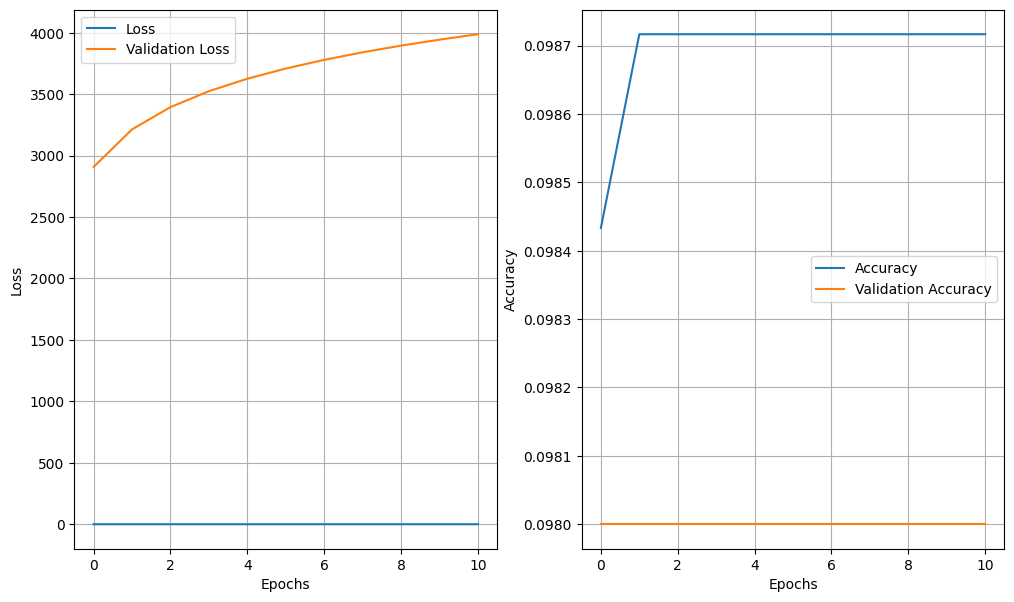